# Telecom Customer Churn – Simple ML Models with Pipelines

This notebook loads the telecom churn dataset, does a little EDA with charts, and then
builds **three models** using scikit‑learn pipelines:

- Decision Tree
- K‑Nearest Neighbors (KNN)
- Random Forest

Each model uses its **own GridSearchCV parameter grid**, and we compare their accuracy.

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

sns.set(style='whitegrid')


# 1. Data Loading and Understanding

Make sure the CSV file is in the same folder as this notebook.
If you are using Google Colab, upload the file in the **Files** panel and
use the correct path.

In [62]:
data_path = data_path = "TelecomCo_ChurnData.csv"

df = pd.read_csv(data_path)
df.head()

,CustomerID,Gender,Age,Tenure,MonthlyCharges,TotalCharges,InternetService,ContractType,PaymentMethod,HasTechSupport,Churn
0,C00001,Male,68,58,98.92,5780.43,DSL,Month-to-month,Electronic check,No,No
1,C00002,Female,64,21,55.85,1196.56,DSL,Month-to-month,Electronic check,Yes,No
2,C00003,Male,64,56,31.83,1788.92,Fiber optic,Month-to-month,Electronic check,No,No
3,C00004,Male,21,20,119.65,2431.67,Fiber optic,Month-to-month,Electronic check,Yes,Yes
4,C00005,Male,24,54,98.73,5347.98,DSL,Month-to-month,Mailed check,Yes,No


## Dropping the CustomerID column

In [63]:
#df.drop(axis=1, columns='CustomerID', inplace=True)


# 2. Exploratory Data Analysis (EDA)

In [64]:
print('Shape:', df.shape)
print('\nData types:')
print(df.dtypes)

print('\nMissing values per column:')
print(df.isna().sum())

print(f'\nTotal Number of Duplicated Values: {df.duplicated().sum()}\n')

Shape: (5000, 11)

Data types:
CustomerID             str
Gender                 str
Age                  int64
Tenure               int64
MonthlyCharges     float64
TotalCharges       float64
InternetService        str
ContractType           str
PaymentMethod          str
HasTechSupport         str
Churn                  str
dtype: object

Missing values per column:
CustomerID         0
Gender             0
Age                0
Tenure             0
MonthlyCharges     0
TotalCharges       0
InternetService    0
ContractType       0
PaymentMethod      0
HasTechSupport     0
Churn              0
dtype: int64

Total Number of Duplicated Values: 0



In [65]:
df.describe()

,Age,Tenure,MonthlyCharges,TotalCharges
count,5000.000000,5000.000000,5000.000000,5000.000000
mean,46.281000,36.076400,70.223678,2536.219906
std,16.471026,20.652328,28.745387,1876.372782
min,18.000000,1.000000,20.010000,-8.400000
25%,32.000000,18.000000,45.647500,1007.572500
50%,46.000000,36.000000,70.525000,2117.690000
75%,61.000000,54.000000,94.727500,3752.485000
max,74.000000,71.000000,119.990000,8434.300000


In [66]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       5000 non-null   str    
 1   Gender           5000 non-null   str    
 2   Age              5000 non-null   int64  
 3   Tenure           5000 non-null   int64  
 4   MonthlyCharges   5000 non-null   float64
 5   TotalCharges     5000 non-null   float64
 6   InternetService  5000 non-null   str    
 7   ContractType     5000 non-null   str    
 8   PaymentMethod    5000 non-null   str    
 9   HasTechSupport   5000 non-null   str    
 10  Churn            5000 non-null   str    
dtypes: float64(2), int64(2), str(7)
memory usage: 658.8 KB


In [67]:
print(f'\nMaximum Total Charges: {df['TotalCharges'].max()}')
print(f'\nMinimum Monthly Charges: {df['MonthlyCharges'].min()}')
print(f'\nContract Types: {df['ContractType'].unique()}')
print(f'\nInternet Services: {df['InternetService'].unique()}')
print(f'\nPayment Methods: {df['PaymentMethod'].unique()}')
print(f'\nAverage Tenure (Months): {df['Tenure'].mean()}')
print(f'\nAverage Age: {df['Age'].mean()}\n')


Maximum Total Charges: 8434.3

Minimum Monthly Charges: 20.01

Contract Types: <ArrowStringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str

Internet Services: <ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

Payment Methods: <ArrowStringArray>
['Electronic check', 'Mailed check', 'Bank transfer', 'Credit card']
Length: 4, dtype: str

Average Tenure (Months): 36.0764

Average Age: 46.281



In [68]:
churn = df['Churn'].map({'No': 0, 'Yes':1})
df['churn'] = churn
df.head()

df.groupby("ContractType")["churn"].value_counts(normalize=True).unstack()


churn,0,1
ContractType,,
Month-to-month,0.720543,0.279457
One year,0.760520,0.239480
Two year,0.739305,0.260695


In [69]:
df.groupby("ContractType")["churn"].mean()

ContractType
Month-to-month    0.279457
One year          0.239480
Two year          0.260695
Name: churn, dtype: float64

In [70]:
df.groupby("InternetService")["churn"].mean()


InternetService
DSL            0.261584
Fiber optic    0.272358
No             0.255159
Name: churn, dtype: float64

# 3. Data Visualization

### Target distribution (Churn)

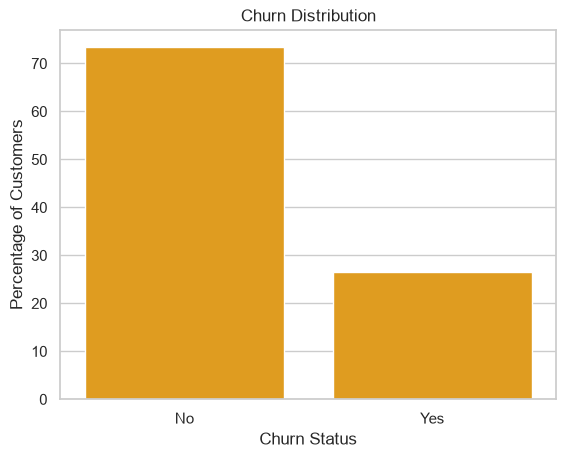

In [71]:
churn_percent = df['Churn'].value_counts(normalize=True) * 100

sns.barplot(
    x=churn_percent.index,
    y=churn_percent.values, color='orange'
)

plt.title("Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Percentage of Customers")
plt.show()

### Proportion of Contract Types

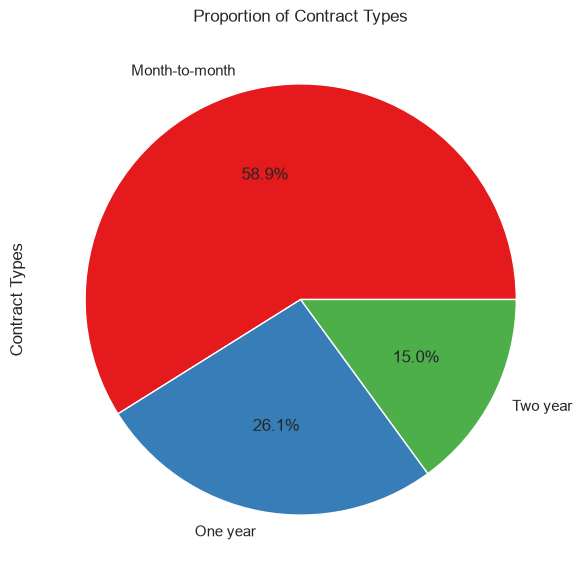

In [72]:
plt.figure(figsize=(10,7))

colors = sns.color_palette("Set1")

df['ContractType'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors = colors)
plt.title("Proportion of Contract Types")
plt.ylabel("Contract Types")
plt.show()

### Churn by Contract Type

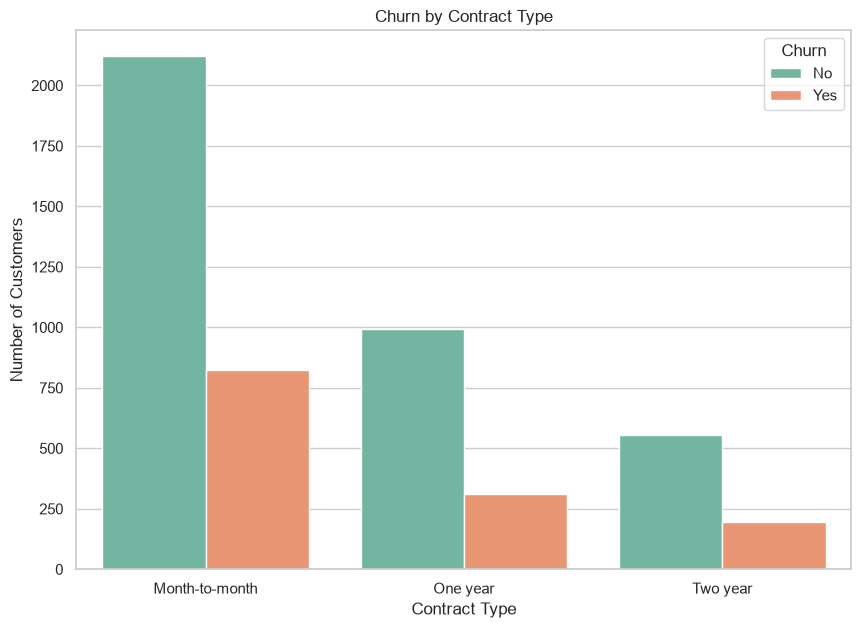

In [73]:
plt.figure(figsize=(10,7))
sns.countplot(data=df, x='ContractType', hue='Churn', palette='Set2')
plt.title("Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")
plt.show()

### Tenure Distribution Based on Churn

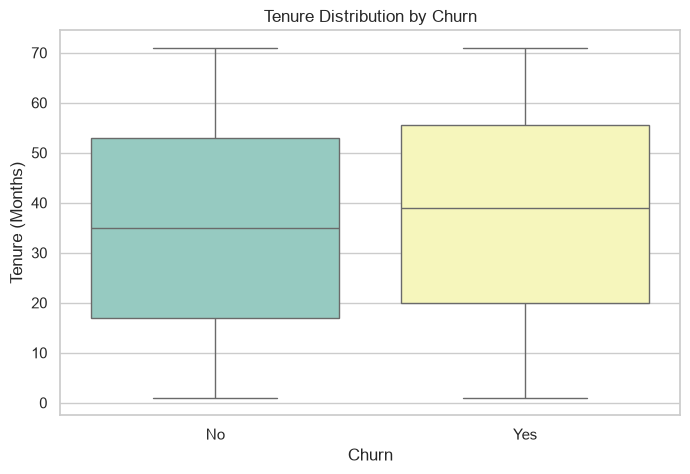

In [74]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Churn', y='Tenure', hue = 'Churn', palette='Set3')
plt.title("Tenure Distribution by Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

### Churn by Internet Service

### Numeric feature distributions

Numeric columns: ['Age', 'Tenure', 'MonthlyCharges', 'TotalCharges']


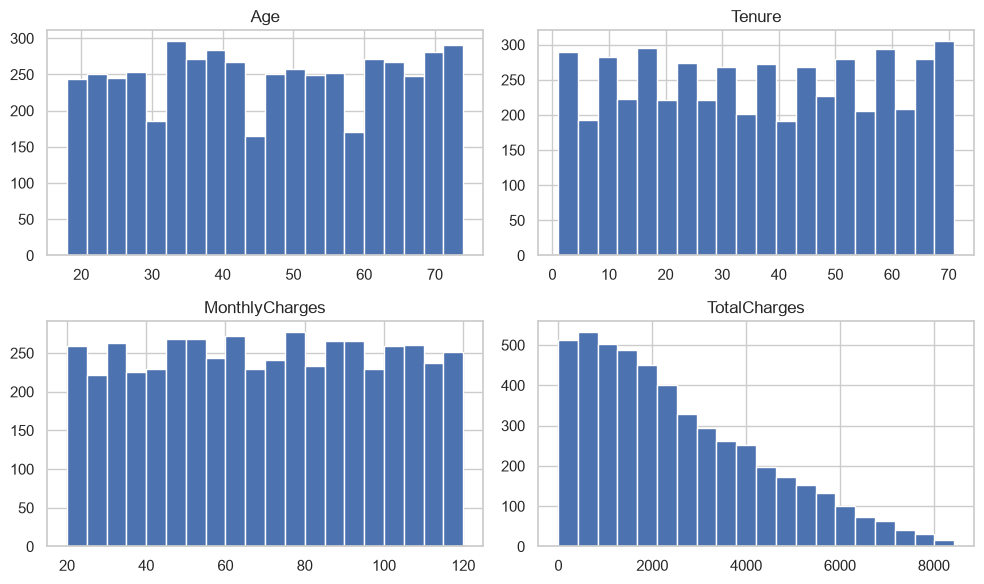

In [75]:
numeric_cols = df.drop(columns='churn').select_dtypes(include=['int64', 'float64']).columns
print('Numeric columns:', list(numeric_cols))

df[numeric_cols].hist(bins=20, figsize=(10,6))
plt.tight_layout()
plt.show()

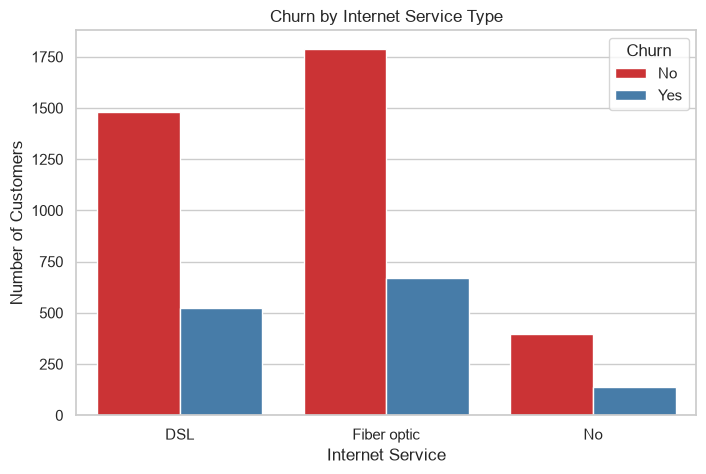

In [76]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='InternetService', hue='Churn', palette='Set1')
plt.title("Churn by Internet Service Type")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")
plt.show()

### Churn Rate by Tenure Group


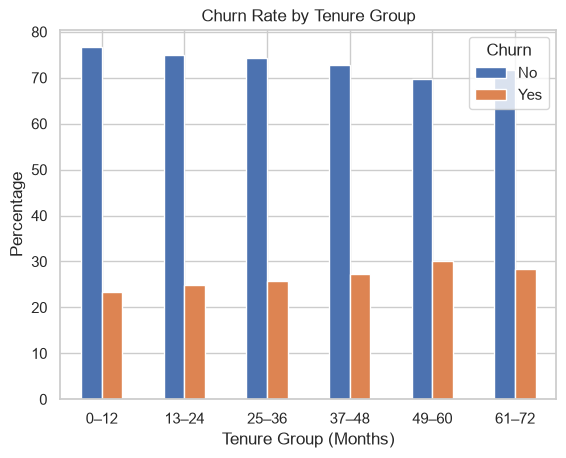

In [77]:
import pandas as pd
import matplotlib.pyplot as plt

bins = [0, 12, 24, 36, 48, 60, 72]
labels = ["0–12", "13–24", "25–36", "37–48", "49–60", "61–72"]
df['TenureGroup'] = pd.cut(df['Tenure'], bins=bins, labels=labels, right=True)

tenure_churn = df.groupby('TenureGroup')['Churn'].value_counts(normalize=True).unstack() * 100
tenure_churn.plot(kind='bar')

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group (Months)")
plt.ylabel("Percentage")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.show()


# 4. Data Preprocessing & Feature Engineering

### Defining variables and splitting data into Training and Testing sets

In [78]:


df.drop(columns='Churn', inplace=True)

X = df.drop('churn', axis=1)
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)


### Standardizing numeric values and encoding categorical variables into dummy variables using ColumnTransformer()

In [79]:
numeric = df.drop(columns='churn').select_dtypes(include=["int64", "float64"]).columns
categorical = df.select_dtypes(include=["object"]).columns

print('Numeric features:', numeric)
print('Categorical features:', categorical)


Numeric features: Index(['Age', 'Tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')
Categorical features: Index(['CustomerID', 'Gender', 'InternetService', 'ContractType',
       'PaymentMethod', 'HasTechSupport'],
      dtype='str')


/var/folders/m8/56wvb6s12fxbn9mn95298g6r0000gn/T/ipykernel_89765/3533287730.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = df.select_dtypes(include=["object"]).columns


### Data Preprocessing

In [80]:
preprocess = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical),
    ]
)

# 5. Model Development & Hyperparameter Tuning

### Defining a function to evaluate models

In [81]:
def evaluate_model(name, best_estimator, X_test, y_test):
    """Print metrics and plot confusion matrix for a model."""
    y_pred = best_estimator.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    print(f"{name} Accuracy: {acc:.4f}\n")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_estimator.classes_)
    disp.plot(cmap='Blues')
    plt.title(f'{name} – Confusion Matrix')
    plt.tight_layout()
    plt.show()

    return acc


## Decision Tree with GridSearchCV

### Creating a pipeline for data prepocessing and building the Model

In [82]:
dt_pipeline = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', DecisionTreeClassifier(random_state=42))
])

### Applying the GridSearchCV method to train the model with the optimum hyperparameters

Best Decision Tree parameters:
{'model__criterion': 'gini', 'model__max_depth': 5, 'model__min_samples_leaf': 4, 'model__min_samples_split': 2}
Decision Tree Accuracy: 0.7247

              precision    recall  f1-score   support

           0       0.73      0.98      0.84      1101
           1       0.21      0.01      0.02       399

    accuracy                           0.72      1500
   macro avg       0.47      0.50      0.43      1500
weighted avg       0.59      0.72      0.62      1500



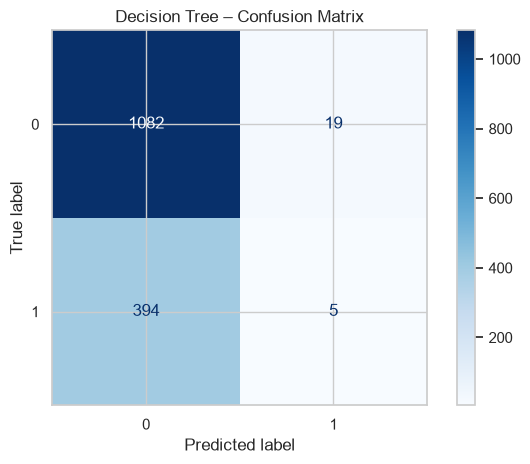

In [83]:
dt_param_grid = {
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [None, 5, 10, 15],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
}

dt_grid = GridSearchCV(
    dt_pipeline,
    dt_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)
print('Best Decision Tree parameters:')
print(dt_grid.best_params_)

dt_acc = evaluate_model('Decision Tree', dt_grid.best_estimator_, X_test, y_test)

## K‑Nearest Neighbors (KNN) with GridSearchCV

### Creating a pipeline for data prepocessing and building the Model

In [84]:
knn_pipeline = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', KNeighborsClassifier())
])


### Applying the GridSearchCV method to train the model with the optimum hyperparameters

Best KNN parameters:
{'model__n_neighbors': 11, 'model__p': 1, 'model__weights': 'uniform'}
KNN Accuracy: 0.7220

              precision    recall  f1-score   support

           0       0.74      0.97      0.84      1101
           1       0.34      0.05      0.09       399

    accuracy                           0.72      1500
   macro avg       0.54      0.51      0.46      1500
weighted avg       0.63      0.72      0.64      1500



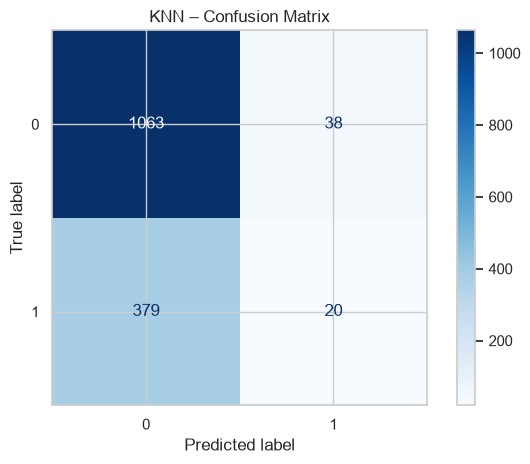

In [85]:
knn_param_grid = {
    'model__n_neighbors': [3, 5, 7, 9, 11],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2],  # 1 = Manhattan, 2 = Euclidean
}

knn_grid = GridSearchCV(
    knn_pipeline,
    knn_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)
print('Best KNN parameters:')
print(knn_grid.best_params_)

knn_acc = evaluate_model('KNN', knn_grid.best_estimator_, X_test, y_test)

## Random Forest with GridSearchCV

### Creating a pipeline for data prepocessing and building the Model

In [86]:
rf_pipeline = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', RandomForestClassifier(random_state=42, class_weight='balanced'))
])


### Applying the GridSearchCV method to train the model with the optimum hyperparameters

Best Random Forest parameters:
{'model__max_depth': None, 'model__max_features': 'log2', 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Random Forest Accuracy: 0.7340

              precision    recall  f1-score   support

           0       0.73      1.00      0.85      1101
           1       0.00      0.00      0.00       399

    accuracy                           0.73      1500
   macro avg       0.37      0.50      0.42      1500
weighted avg       0.54      0.73      0.62      1500



/opt/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


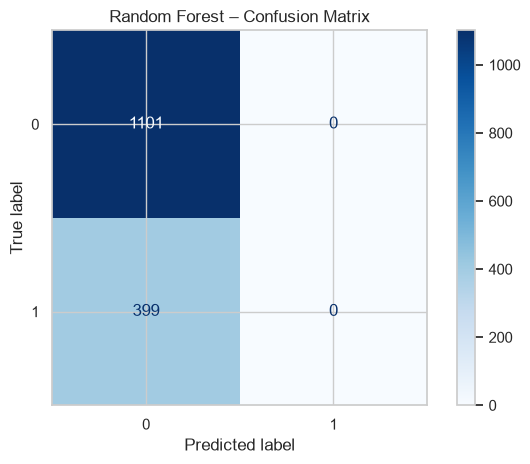

In [87]:
rf_param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 5, 10, 15],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 'log2'],
}

rf_grid = GridSearchCV(
    rf_pipeline,
    rf_param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)
print('Best Random Forest parameters:')
print(rf_grid.best_params_)

rf_acc = evaluate_model('Random Forest', rf_grid.best_estimator_, X_test, y_test)

In [89]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

for name, m in [
    ("LogReg balanced", LogisticRegression(class_weight="balanced", max_iter=1000)),
    ("RF balanced", RandomForestClassifier(class_weight="balanced_subsample", min_samples_leaf=10, n_estimators=200, random_state=42)),
]:
    p = clone(rf_pipeline).set_params(model=m)
    p.fit(X_train, y_train)
    print(name); print(classification_report(y_test, p.predict(X_test)))

LogReg balanced
              precision    recall  f1-score   support

           0       0.73      0.88      0.80      1101
           1       0.24      0.11      0.15       399

    accuracy                           0.67      1500
   macro avg       0.49      0.49      0.47      1500
weighted avg       0.60      0.67      0.63      1500

RF balanced
              precision    recall  f1-score   support

           0       0.72      0.50      0.59      1101
           1       0.26      0.47      0.33       399

    accuracy                           0.49      1500
   macro avg       0.49      0.49      0.46      1500
weighted avg       0.60      0.49      0.52      1500



# 6. Model Evaluation & Comparison

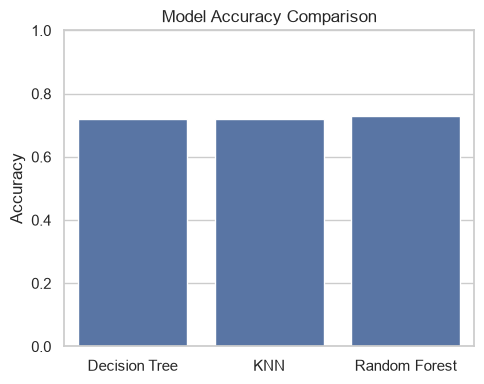

{'Decision Tree': 0.72, 'KNN': 0.72, 'Random Forest': 0.73}

In [88]:
model_scores = {
    'Decision Tree': round(dt_acc,2),
    'KNN': round(knn_acc,2),
    'Random Forest': round(rf_acc,2),
}

plt.figure(figsize=(5,4))
sns.barplot(x=list(model_scores.keys()), y=list(model_scores.values()))
plt.ylim(0, 1)
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')
plt.tight_layout()
plt.show()

model_scores